In [ ]:
import numpy as np
import plotly.express as px

t = np.linspace(0, 10, 100)
w = 50
x = np.sin(w * t) + np.sin(4*w*t) + np.sin(3*w*t)
y = w * np.cos(w*t)

fig = px.line(
    x=x,
    y=y
)

fig.show(
)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate a mock 1D vibration signal (e.g., two combined frequencies with some noise)
t = np.linspace(0, 50, 5000)
signal_1d = np.sin(2.1 * t) + 0.5 * np.cos(4.3 * t)

# 2. Define the delay (tau)
# In practice, this is chosen carefully, but we'll use an arbitrary step for the example
tau = 50 

# 3. Create the delayed arrays (Takens' Embedding for m=2)
x_original = signal_1d[:-tau]      # X(t)
x_delayed = signal_1d[tau:]        # X(t + tau)

fig = px.line(
    x = t,
    y = signal_1d,
)

fig.update_layout(
    height=600,
    width=600,
)

fig

statistic,Original,Escalado
str,f64,f64
"""count""",10000.0,10000.0
"""null_count""",0.0,0.0
"""mean""",1.00146,null
"""std""",1.001768,null
"""min""",0.000088,null
"""25%""",0.295486,null
"""50%""",0.692489,null
"""75%""",1.383181,null
"""max""",9.264842,null


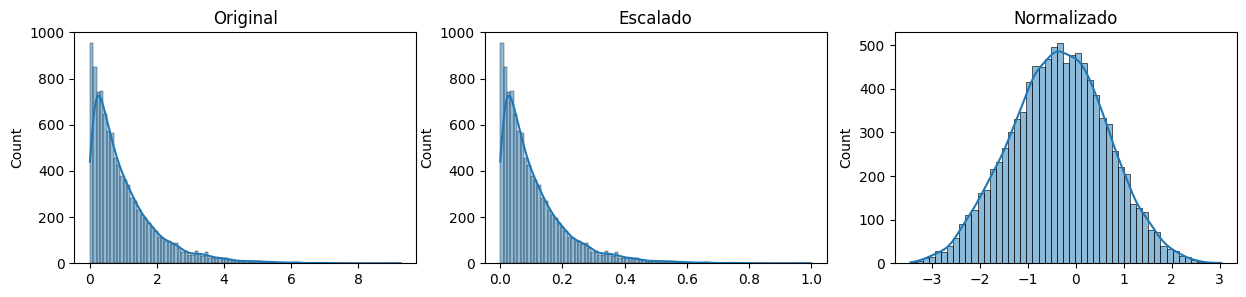

In [ ]:
import numpy as np  # Para gerar os dados aleatórios
import seaborn as sns  # Para os gráficos estatísticos (histplot)
import matplotlib.pyplot as plt  # Para criar a figura e os eixos (subplots)
from scipy import stats  # Para a função Box-Cox (normalização)
from mlxtend.preprocessing import minmax_scaling  # Para o escalonamento entre 0 e 1
import polars as pl

datanew = np.random.exponential(size= 10000) #--> retorna valores aleatorios
scaled = minmax_scaling(datanew, columns=[0]) #---> escala eles entre 0 e 1 (0 o menor e 1 o maior, os outros no meio na mesma proporção)
normalized_data = stats.boxcox(datanew)
fig, ax = plt.subplots(1,3, figsize= (15,3)) #--> cria gráfico de 1 linha e 2 colunas
 
sns.histplot(datanew, ax=ax[0], kde= True, legend= False) # gráfico com a datanew na coluna ax = 0, KDE faz a linha
sns.histplot(scaled, ax=ax[1], kde= True, legend= False) # gráfico com a scaled na coluna ax = 0, KDE faz a linha
sns.histplot(normalized_data, ax=ax[2], kde= True, legend= False) # gráfico com a normalized na coluna ax = 0, KDE faz a linha
ax[0].set_title("Original")
ax[1].set_title("Escalado")
ax[2].set_title("Normalizado")
 
df = {
    "Original": datanew,
    "Escalado": scaled,
    "Normalizado": normalized_data
}

pl.DataFrame(df).describe()

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

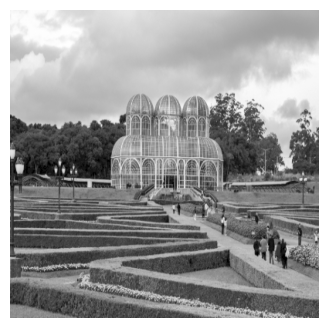

In [2]:
image_path = r'C:\soft\Personal\cv_vibrometry\Code\Images\jardim botanico.png'
image = tf.io.read_file(image_path)
image = tf.io.decode_jpeg(image, channels=1)
image = tf.image.resize(image, size=[400, 400])

img = tf.squeeze(image).numpy()
plt.figure(figsize=(10, 4))
plt.imshow(img, cmap="grey")
plt.axis('off')
plt.show()


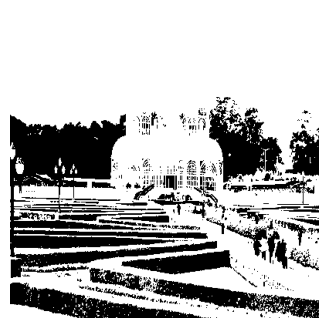

In [3]:


img = tf.squeeze(image).numpy()
for i in range(len(img)):
    img = img * (i+1)/131.9999923706
    ultimo = img
plt.figure(figsize=(10, 4))
plt.imshow(ultimo, cmap='grey')
plt.axis('off')
plt.show()

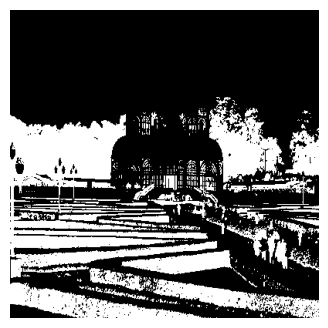

In [4]:


img = tf.squeeze(image).numpy()
nova = img - ultimo

plt.figure(figsize=(10, 4))
plt.imshow(nova, cmap='grey')
plt.axis('off')
plt.show()

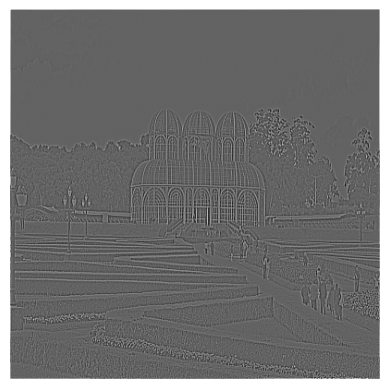

In [5]:
import tensorflow as tf
import matplotlib.pyplot as plt

image_path = r'C:\soft\Personal\cv_vibrometry\Code\Images\jardim botanico.png'
image = tf.io.read_file(image_path)
image = tf.io.decode_jpeg(image, channels=1)
image = tf.image.resize(image, size=[400, 400])

image = tf.squeeze(image)
image = tf.image.convert_image_dtype(image, dtype=tf.float32)

image = tf.expand_dims(image, axis=-1)   
image = tf.expand_dims(image, axis=0)    

kernel = tf.constant([
    [-1, -1, -1],
    [-1, 8, -1],
    [-1, -1, -1],
], dtype=tf.float32)


kernel = tf.reshape(kernel, [3, 3, 1, 1])

image_filter = tf.nn.conv2d(
    input=image,
    filters=kernel,
    strides=[1, 1, 1, 1],
    padding='SAME',
)

plt.imshow(tf.squeeze(image_filter), cmap='gray')
plt.axis('off')
plt.show()

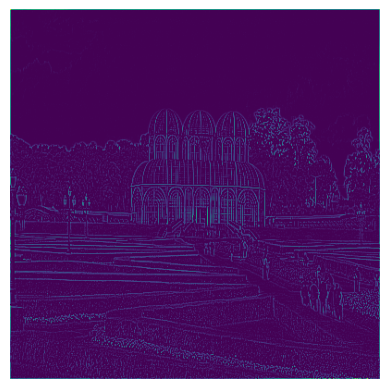

In [6]:

relu_fn = tf.nn.relu

image_detect = relu_fn(image_filter)

plt.imshow(
    
    tf.squeeze(image_detect)
)
plt.axis('off')
plt.show()

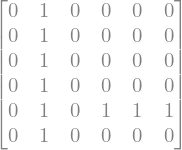

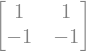

In [1]:
# Sympy is a python library for symbolic mathematics. It has a nice
# pretty printer for matrices, which is all we'll use it for.
import numpy as np
import tensorflow as tf
import sympy
sympy.init_printing()
from IPython.display import display

image = np.array([
    [0, 1, 0, 0, 0, 0],
    [0, 1, 0, 0, 0, 0],
    [0, 1, 0, 0, 0, 0],
    [0, 1, 0, 0, 0, 0],
    [0, 1, 0, 1, 1, 1],
    [0, 1, 0, 0, 0, 0],
])

kernel = np.array([
    [1, 1],
    [-1, -1],
])

display(sympy.Matrix(image))
display(sympy.Matrix(kernel))
# Reformat for Tensorflow
image = tf.cast(image, dtype=tf.float32)
image = tf.reshape(image, [1, *image.shape, 1])
kernel = tf.reshape(kernel, [*kernel.shape, 1, 1])
kernel = tf.cast(kernel, dtype=tf.float32)

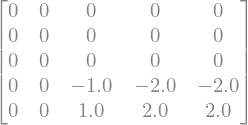

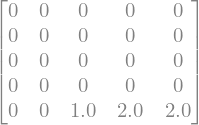

In [2]:
image_filter = tf.nn.conv2d(
    input=image,
    filters=kernel,
    strides=1,
    padding='VALID',
)
image_detect = tf.nn.relu(image_filter)

display(sympy.Matrix(tf.squeeze(image_filter).numpy()))
display(sympy.Matrix(tf.squeeze(image_detect).numpy()))

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import map_coordinates

def conformal_map_image(image_path, inverse_func, output_range=(-2, 2, -2, 2), resolution=800):
    """
    Aplica um mapeamento conforme em uma imagem através de mapeamento reverso.
    """
    # 1. Carregar imagem original (Plano Z)
    img = Image.open(image_path).convert('RGB')
    img_array = np.array(img)
    h, w_img, _ = img_array.shape

    # 2. Criar a grade do plano de saída (Plano W)
    u_min, u_max, v_min, v_max = output_range
    U, V = np.meshgrid(
        np.linspace(u_min, u_max, resolution),
        np.linspace(v_min, v_max, resolution)
    )
    W = U + 1j * V  # Grade complexa w = u + iv

    # 3. Mapeamento Reverso: Z = f^{-1}(W)
    # Descobrimos de onde cada ponto do plano W veio no plano Z original
    Z = inverse_func(W)

    # 4. Converter as coordenadas complexas Z para os índices da matriz da imagem original
    # Assumindo que a imagem original preenchia o domínio complexo padrão [-2, 2] nos eixos real e imaginário
    z_real_min, z_real_max = -2, 2
    z_imag_min, z_imag_max = -2, 2
    
    x_coords = (Z.real - z_real_min) / (z_real_max - z_real_min) * (w_img - 1)
    y_coords = (Z.imag - z_imag_min) / (z_imag_max - z_imag_min) * (h - 1)
    
    # Inverter o eixo Y porque matrizes de imagem (0,0) começam no canto superior esquerdo
    y_coords = (h - 1) - y_coords 

    # Empilhar coordenadas para o map_coordinates
    coords = np.array([y_coords.ravel(), x_coords.ravel()])

    # 5. Interpolação de cor
    mapped_img = np.zeros((resolution, resolution, 3), dtype=np.uint8)
    for i in range(3): # Para cada canal (R, G, B)
        # Interpolação bilinear (order=1). Áreas fora do domínio ficam pretas (cval=0)
        mapped_channel = map_coordinates(img_array[:, :, i], coords, order=1, mode='constant', cval=0)
        mapped_img[:, :, i] = mapped_channel.reshape((resolution, resolution))

    return mapped_img

# ==========================================
# Funções Inversas para Teste
# Se queremos ver w = f(z), programamos z = f^{-1}(w)
# ==========================================

# A estrela do vídeo do 3b1b: w = ln(z) -> A inversa é z = e^w
def inv_log(w):
    return np.exp(w)

# Transformação quadrática: w = z^2 -> A inversa é z = sqrt(w)
def inv_square(w):
    return np.sqrt(w)

# Transformação de inversão: w = 1/z -> A inversa é z = 1/w
def inv_inverse(w):
    # Adicionamos um epsilon pequeno para evitar divisão por zero
    return 1 / (w + 1e-8)

# ==========================================
# Execução (Descomente para rodar localmente)
# ==========================================
if __name__ == "__main__":
    pass
    # Caminho para sua foto
    # img_path = 'sua_foto.jpg'
    
    # Aplicando a transformação logarítmica w = ln(z)
    # No vídeo, o logaritmo desdobra os ângulos, então o domínio de saída em Y ideal é de -pi a pi
    # result_img = conformal_map_image(img_path, inv_log, output_range=(-2, 2, -np.pi, np.pi))
    
    # plt.figure(figsize=(8, 8))
    # plt.imshow(result_img)
    # plt.axis('off')
    # plt.title("Mapeamento: w = ln(z)")
    # plt.show()

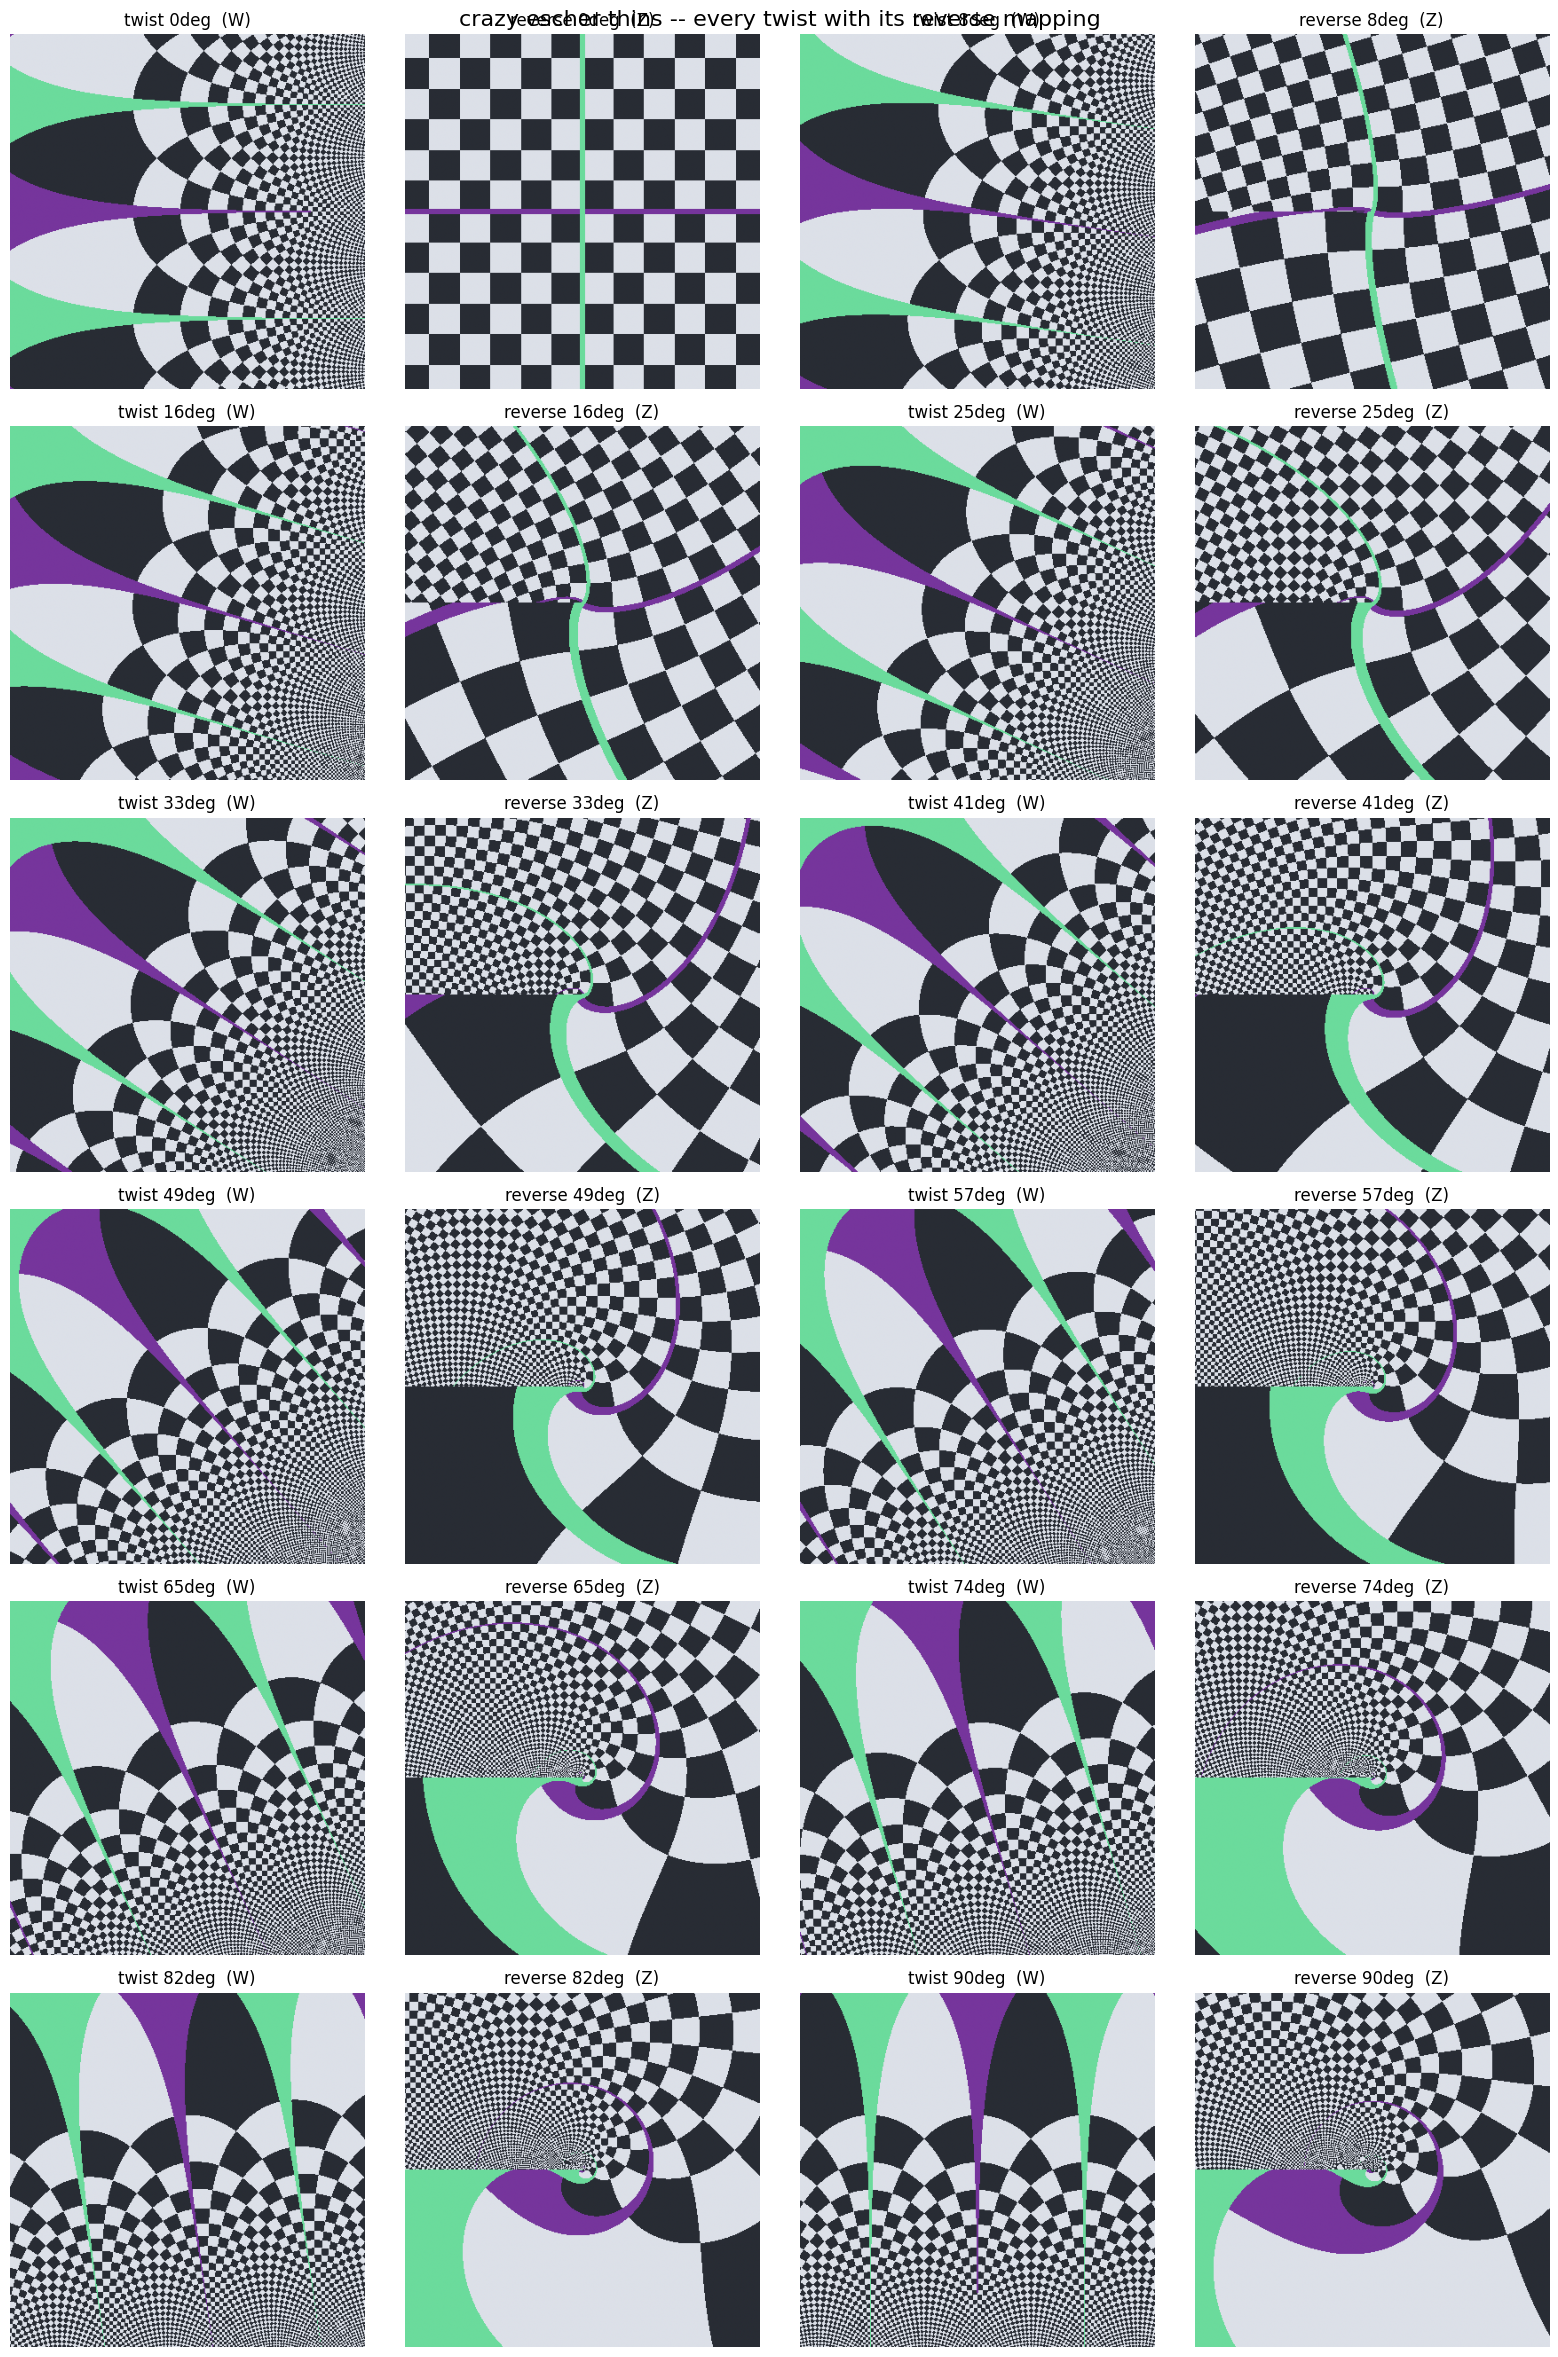

In [10]:
#crazy escher thins
import numpy as np
import matplotlib.pyplot as plt

# In theoretical mathematics, both the Z plane and the W plane are completely
# infinite. There are no black spaces, no abrupt cuts, and no missing data.
#
# The old version contradicted that: it sampled a FINITE raster picture with
# map_coordinates(mode='constant', cval=0) and rotated it with reshape=False,
# so anything that fell off the edge became a black hole.
#
# Fix: never sample a finite image. Evaluate the pattern ANALYTICALLY straight
# from the (real, imaginary) coordinates, so every single point of the plane
# has a colour -- forever. Both the forward twist AND its reverse mapping then
# stay completely filled: no black spaces, no abrupt cuts, no missing data.
def escher_texture(zr, zi, period=0.45):
    checker = (np.floor(zr / period) + np.floor(zi / period)) % 2
    dark  = np.array([40, 44, 52]) / 255.0
    light = np.array([220, 224, 232]) / 255.0
    img = np.where(checker[..., None] == 0, dark, light)
    # thin coloured guide-lines so the twist is easy to follow (still no black)
    img = np.where((np.abs(zi) < 0.04)[..., None], np.array([118, 53, 156]) / 255.0, img)  # eixo x
    img = np.where((np.abs(zr) < 0.04)[..., None], np.array([107, 219, 156]) / 255.0, img)  # eixo y
    return img

# w = ln(z) unrolls the plane into a strip; rotating that strip by `angle` and
# exponentiating back twists straight lines into logarithmic spirals.
#   forward  : screen is the W (log) plane ->  z = exp(w * e^{+i*theta})
#   reverse  : screen is the Z plane back   ->  z = exp(e^{-i*theta} * ln w)
# The reverse mapping closes the loop, showing the same twist re-expressed in
# real (Z-plane) coordinates -- the classic Escher / Droste spiral.
def escher_panel(angle_deg, reverse=False, span=2.6, resolution=400):
    a = np.linspace(-span, span, resolution)
    A, B = np.meshgrid(a, a)
    G = A + 1j * B
    theta = np.deg2rad(angle_deg)
    if not reverse:
        Z = np.exp(G * np.exp(1j * theta))            # forward: W-plane view
    else:
        G = np.where(G == 0, 1e-12, G)                # ln is undefined at the origin
        Z = np.exp(np.exp(-1j * theta) * np.log(G))   # reverse: Z-plane view
    return escher_texture(Z.real, Z.imag)

# Sweep the twist angle; for every twist show the forward map AND its reverse.
angles = np.linspace(0, 90, 12)              # change count/range for more variety
ncols = 4                                    # columns alternate forward / reverse
nrows = int(np.ceil(2 * len(angles) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows))
flat = axes.ravel()
for i, angle in enumerate(angles):
    flat[2 * i].imshow(escher_panel(angle, reverse=False), origin='lower')
    flat[2 * i].set_title(f"twist {angle:.0f}deg  (W)")
    flat[2 * i].axis('off')
    flat[2 * i + 1].imshow(escher_panel(angle, reverse=True), origin='lower')
    flat[2 * i + 1].set_title(f"reverse {angle:.0f}deg  (Z)")
    flat[2 * i + 1].axis('off')
for ax in flat[2 * len(angles):]:
    ax.axis('off')

fig.suptitle("crazy escher thins -- every twist with its reverse mapping", fontsize=16)
plt.tight_layout()
plt.show()
